In [1]:
import pandas as pd
from datetime import datetime
import os
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [2]:
# Load the CSV file into a pandas DataFrame
cPath = os.path.dirname(os.path.realpath('./New/'))
file_path = cPath + '/Combined_Terminal_Label.csv'
print(file_path)
myData = pd.read_csv(file_path, parse_dates=['DateTime'], date_format='%Y-%m-%d %H:%M:%S')
myData.set_index('DateTime', drop = False, inplace=True)
# print(myData.head)
# print(myData.index.name)
# print(myData.columns)
# print(myData.dtypes)
# print(myData.describe())
# print(myData.info())
print(myData.head(3))
print(myData.tail(3))
#print(myData)

/Users/hv/Dropbox/Projects/VisualCode/Python/CAE/New/KWH_based/Combined_Terminal_Label.csv
                               DateTime  KWH11    KW  Year     Delta     label
DateTime                                                                      
2014-07-01 00:14:00 2014-07-01 00:14:00  357.5  1430  2014  0.005000  sOffPeak
2014-07-01 00:29:00 2014-07-01 00:29:00  362.0  1448  2014 -0.012778  sOffPeak
2014-07-01 00:44:00 2014-07-01 00:44:00  350.5  1402  2014 -0.006667  sOffPeak
                               DateTime  KWH11   KW  Year     Delta     label
DateTime                                                                     
2024-12-31 23:29:00 2024-12-31 23:29:00  211.0  844  2024  0.008889  wOffPeak
2024-12-31 23:44:00 2024-12-31 23:44:00  219.0  876  2024 -0.027778  wOffPeak
2024-12-31 23:59:00 2024-12-31 23:59:00  194.0  776  2024  0.000000  wOffPeak


In [3]:
# Convert 15-minute KWH11 data to hourly usage by summing values for each day
hourlyUsage = myData.groupby(myData['DateTime'].dt.floor('h'))['KWH11'].sum().reset_index()
hourlyUsage.columns = ['Date', 'hourly_KWH']
hourlyUsage['Date'] = pd.to_datetime(hourlyUsage['Date'])
hourlyUsage.set_index('Date', inplace=True)

print(f"hourly usage data shape: {hourlyUsage.shape}")
print(hourlyUsage.head())
print(hourlyUsage.tail())

hourly usage data shape: (92065, 1)
                     hourly_KWH
Date                           
2014-07-01 00:00:00      1414.5
2014-07-01 01:00:00      1296.5
2014-07-01 02:00:00      1294.5
2014-07-01 03:00:00      1297.5
2014-07-01 04:00:00      1327.0
                     hourly_KWH
Date                           
2024-12-31 19:00:00       485.5
2024-12-31 20:00:00       490.0
2024-12-31 21:00:00       633.0
2024-12-31 22:00:00       858.0
2024-12-31 23:00:00       822.5


In [4]:
# Check for duplicated time indices in hourlyUsage due to time change
duplicated_indices = hourlyUsage.index.duplicated()
print("Any duplicated time indices:", duplicated_indices.any())
if duplicated_indices.any():
    print("Duplicated indices:", hourlyUsage.index[duplicated_indices])

Any duplicated time indices: False


In [5]:
# Check for NaN values in hourlyUsage DataFrame
print("Any NaN in hourlyUsage:", hourlyUsage.isna().any().any())
print("Columns with NaN:", hourlyUsage.isna().sum())
print("Rows with NaN:", hourlyUsage[hourlyUsage.isna().any(axis=1)])

Any NaN in hourlyUsage: False
Columns with NaN: hourly_KWH    0
dtype: int64
Rows with NaN: Empty DataFrame
Columns: [hourly_KWH]
Index: []


In [13]:
# prepare sliding-window inputs (last 7*24 hours) to predict next 24 hours
# uses existing `hourlyUsage` DataFrame

input_hours = 7 * 24
output_hours = 24

# ensure hourly index and sorted
series = hourlyUsage['hourly_KWH'].sort_index().asfreq('h')

n = len(hourlyUsage)
X = []
y = []
y_start_dates = []

print(0, n, input_hours, output_hours, n-input_hours-output_hours+1)
for i in range(0, n - input_hours - output_hours + 1, 24):  # step by 24 to predict daily, adjust if you want more overlap
    X.append(hourlyUsage[i : i + input_hours-1].values.flatten())
    y.append(hourlyUsage[i + input_hours : i + input_hours + output_hours-1].values.flatten())
    y_start_dates.append(series.index[i + input_hours])  # timestamp for start of prediction window

#print('y[0]:', y[0])  # example input features (168 hours)
#print('X[1]:', X[1])  # example target values (next 24 hours)
print(type(X), type(y), type(y_start_dates))

# Create sequences of 168 hours to predict the next hour
X = np.array(X)           # shape: (n_samples, 168)
y = np.array(y)           # shape: (n_samples, 24)
y_start_dates = pd.to_datetime(y_start_dates)

print("X.shape:", X.shape)
print("y.shape:", y.shape)
print('y_start_dates.shape:', y_start_dates.shape)
print("example target start:", y_start_dates[0])

0 92065 168 24 91874
<class 'list'> <class 'list'> <class 'list'>
X.shape: (3829, 167)
y.shape: (3829, 23)
y_start_dates.shape: (3829,)
example target start: 2014-07-08 00:00:00


In [11]:
# Split data into training and testing sets based on year 2024
test_mask = y_start_dates.year == 2024
train_mask = ~test_mask

X_train = X[train_mask]
y_train = y[train_mask]
X_test = X[test_mask]
y_test = y[test_mask]

print(f"Training set size: X_train {X_train.shape}, y_train {y_train.shape}")
print(f"Testing set size: X_test {X_test.shape}, y_test {y_test.shape}")
# Find indices in X_train with NaN values
nan_indices = np.where(np.isnan(X_train))[0]
print("Indices in X_train with NaN:", nan_indices)
# Find indices in X_train with NaN values
nan_indices = np.where(np.isnan(X_train))[0]
print("Indices in X_train with NaN:", nan_indices)

Training set size: X_train (3464, 167), y_train (3464, 0)
Testing set size: X_test (366, 167), y_test (366, 0)
Indices in X_train with NaN: []
Indices in X_train with NaN: []


In [12]:
# Train a linear regression model
model = LinearRegression()
model.fit(X_train, y_train)

# Make predictions on both training and testing sets
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

# Calculate performance metrics
train_mse = mean_squared_error(y_train, y_train_pred)
test_mse = mean_squared_error(y_test, y_test_pred)
train_r2 = r2_score(y_train, y_train_pred)
test_r2 = r2_score(y_test, y_test_pred)

print(f"Training Set Performance:")
print(f"  MSE: {train_mse:.2f}")
print(f"  R² Score: {train_r2:.4f}")
print(f"\nTesting Set Performance:")
print(f"  MSE: {test_mse:.2f}")
print(f"  R² Score: {test_r2:.4f}")

ValueError: Found array with 0 feature(s) (shape=(3464, 0)) while a minimum of 1 is required by LinearRegression.

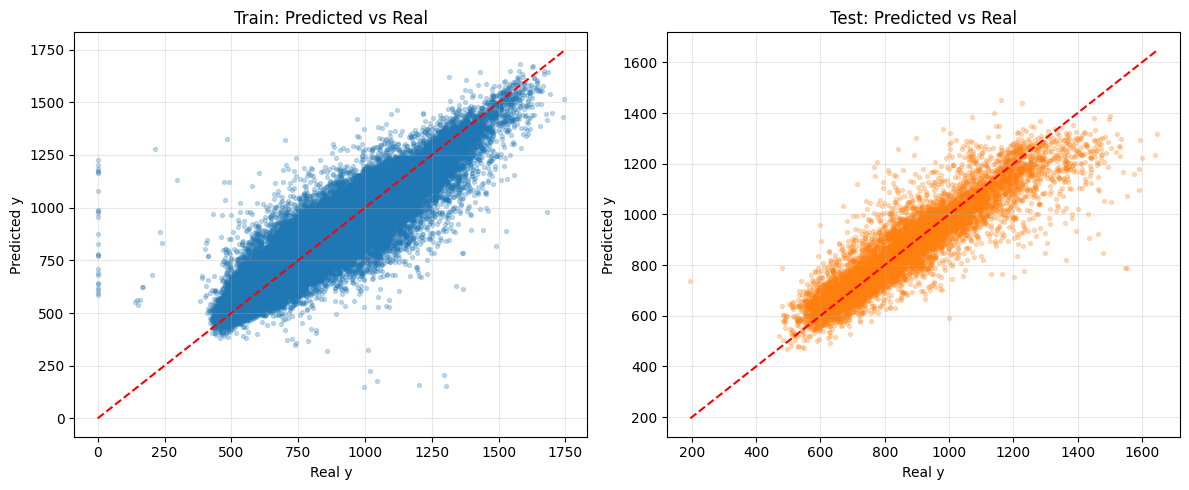

In [9]:
# Plot predicted vs real values (train and test)
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=False, sharey=False)

# Train scatter
true_train = y_train.flatten()
pred_train = y_train_pred.flatten()
axes[0].scatter(true_train, pred_train, s=8, alpha=0.25)
min_t, max_t = true_train.min(), true_train.max()
axes[0].plot([min_t, max_t], [min_t, max_t], 'r--', linewidth=1.5)
axes[0].set_title("Train: Predicted vs Real")
axes[0].set_xlabel("Real y")
axes[0].set_ylabel("Predicted y")
axes[0].grid(alpha=0.3)

# Test scatter
true_test = y_test.flatten()
pred_test = y_test_pred.flatten()
axes[1].scatter(true_test, pred_test, s=8, alpha=0.25, color="tab:orange")
min_v, max_v = true_test.min(), true_test.max()
axes[1].plot([min_v, max_v], [min_v, max_v], 'r--', linewidth=1.5)
axes[1].set_title("Test: Predicted vs Real")
axes[1].set_xlabel("Real y")
axes[1].set_ylabel("Predicted y")
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [9]:
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

# MLP model (with scaling) for multi-output regression
mlp_model = make_pipeline(
    StandardScaler(),
    MLPRegressor(
        hidden_layer_sizes=(32, 8),
        activation='relu',
        solver='adam',
        alpha=1e-4,
        learning_rate_init=1e-3,
        max_iter=1000,
        early_stopping=True,
        validation_fraction=0.1,
        n_iter_no_change=20,
        random_state=42
    )
)

# Train
mlp_model.fit(X_train, y_train)

# Predict
y_train_pred_mlp = mlp_model.predict(X_train)
y_test_pred_mlp = mlp_model.predict(X_test)

# Evaluate
train_mse_mlp = mean_squared_error(y_train, y_train_pred_mlp)
test_mse_mlp = mean_squared_error(y_test, y_test_pred_mlp)
train_r2_mlp = r2_score(y_train, y_train_pred_mlp)
test_r2_mlp = r2_score(y_test, y_test_pred_mlp)

print("MLP Training Set Performance:")
print(f"  MSE: {train_mse_mlp:.2f}")
print(f"  R² Score: {train_r2_mlp:.4f}")

print("\nMLP Testing Set Performance:")
print(f"  MSE: {test_mse_mlp:.2f}")
print(f"  R² Score: {test_r2_mlp:.4f}")

MLP Training Set Performance:
  MSE: 5975.63
  R² Score: 0.8314

MLP Testing Set Performance:
  MSE: 11570.77
  R² Score: 0.5491


/Library/Frameworks/Python.framework/Versions/3.14/lib/python3.14/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


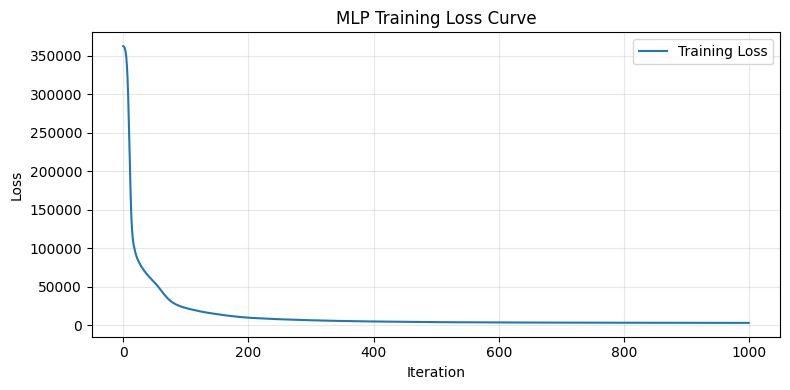

In [10]:
# Plot MLP training loss curve
mlp = mlp_model.named_steps['mlpregressor']

plt.figure(figsize=(8, 4))
plt.plot(mlp.loss_curve_, label='Training Loss')
plt.title('MLP Training Loss Curve')
plt.xlabel('Iteration')
plt.ylabel('Loss')
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [18]:
from sklearn.svm import SVR
from sklearn.multioutput import MultiOutputRegressor

# SVR model (scaled + wrapped for multi-output regression)
svr_model = make_pipeline(
    StandardScaler(),
    MultiOutputRegressor(
        SVR(
            kernel='rbf',
            C=50.0,
            epsilon=0.1,
            gamma='scale'
        )
    )
)

# Train
svr_model.fit(X_train, y_train)

# Predict
y_train_pred_svr = svr_model.predict(X_train)
y_test_pred_svr = svr_model.predict(X_test)

# Evaluate
train_mse_svr = mean_squared_error(y_train, y_train_pred_svr)
test_mse_svr = mean_squared_error(y_test, y_test_pred_svr)
train_r2_svr = r2_score(y_train, y_train_pred_svr)
test_r2_svr = r2_score(y_test, y_test_pred_svr)

print("SVR Training Set Performance:")
print(f"  MSE: {train_mse_svr:.2f}")
print(f"  R² Score: {train_r2_svr:.4f}")

print("\nSVR Testing Set Performance:")
print(f"  MSE: {test_mse_svr:.2f}")
print(f"  R² Score: {test_r2_svr:.4f}")

SVR Training Set Performance:
  MSE: 5700.11
  R² Score: 0.8405

SVR Testing Set Performance:
  MSE: 10254.85
  R² Score: 0.6115


In [ ]:
from sklearn.neighbors import KNeighborsRegressor

# KNN model (with scaling) for multi-output regression
knn_model = make_pipeline(
    StandardScaler(),
    KNeighborsRegressor(
        n_neighbors=7,
        weights='distance',
        metric='minkowski',
        p=2
    )
)

# Train
knn_model.fit(X_train, y_train)

# Predict
y_train_pred_knn = knn_model.predict(X_train)
y_test_pred_knn = knn_model.predict(X_test)

# Evaluate
train_mse_knn = mean_squared_error(y_train, y_train_pred_knn)
test_mse_knn = mean_squared_error(y_test, y_test_pred_knn)
train_r2_knn = r2_score(y_train, y_train_pred_knn)
test_r2_knn = r2_score(y_test, y_test_pred_knn)

print("KNN Training Set Performance:")
print(f"  MSE: {train_mse_knn:.2f}")
print(f"  R² Score: {train_r2_knn:.4f}")

print("\nKNN Testing Set Performance:")
print(f"  MSE: {test_mse_knn:.2f}")
print(f"  R² Score: {test_r2_knn:.4f}")

KNN Training Set Performance:
  MSE: 0.00
  R² Score: 1.0000

KNN Testing Set Performance:
  MSE: 13620.90
  R² Score: 0.4337


In [13]:
# Summarize model performance in a comparison table
results = pd.DataFrame({
    "Model": ["Linear Regression", "MLP", "SVR", "KNN"],
    "Train MSE": [train_mse, train_mse_mlp, train_mse_svr, train_mse_knn],
    "Test MSE": [test_mse, test_mse_mlp, test_mse_svr, test_mse_knn],
    "Train R2": [train_r2, train_r2_mlp, train_r2_svr, train_r2_knn],
    "Test R2": [test_r2, test_r2_mlp, test_r2_svr, test_r2_knn],
})

# Optional extra diagnostics
results["R2 Gap (Train-Test)"] = results["Train R2"] - results["Test R2"]
results["MSE Ratio (Test/Train)"] = results["Test MSE"] / results["Train MSE"]

# Sort by generalization performance
results = results.sort_values(by="Test R2", ascending=False).reset_index(drop=True)

display(results.round(4))

,Model,Train MSE,Test MSE,Train R2,Test R2,R2 Gap (Train-Test),MSE Ratio (Test/Train)
0,Linear Regression,6417.7721,7281.4300,0.8182,0.7369,0.0813,1.134600e+00
1,MLP,5975.6333,11570.7706,0.8314,0.5491,0.2823,1.936300e+00
2,SVR,7991.4672,11604.8506,0.7813,0.5430,0.2382,1.452200e+00
3,KNN,0.0000,14199.8804,1.0000,0.4100,0.5900,3.989167e+13
